# Principal component analysis of the environmental conditions associated with coral bleaching

**Methodology notebook · research question 2**

> *Can dimensionality reduction reveal the major environmental patterns associated with bleaching severity?*

## Objective and approach

Principal component analysis (PCA) is used to summarise the correlated environmental variables recorded for each coral survey sample into a small number of uncorrelated components. PCA is *unsupervised*: the components are computed from the environmental variables alone, without any use of the bleaching values. Bleaching severity is introduced only afterwards, to ask whether the components that the PCA found are the ones that differ between lightly and heavily bleached samples. The analysis therefore proceeds in four stages:

1. **Extraction.** Fit the PCA on the standardised environmental variables and decide how many components to retain (Step 3).
2. **Interpretation.** Read each component from its loadings, i.e. decide which environmental processes it describes (Step 4).
3. **Association with bleaching.** Test whether, and how strongly, the components separate samples with high bleaching from samples with low bleaching, and how much of that separation survives the dimension reduction (Steps 5 and 6).
4. **Validity.** Use the categorical columns (data source, region, ocean, exposure) to check that the components describe environmental patterns rather than differences between survey programmes (Steps 7 to 10).

## Operational definitions

| Term | Definition used in this notebook |
|---|---|
| Environmental variable | One of the numeric satellite-derived and site variables retained after preprocessing (temperature, temperature anomalies, thermal stress, degree heating weeks, turbidity, depth, distance to shore, cyclone frequency, wind speed). The exact list is read from the metadata of the preprocessing notebook. |
| Bleaching severity | `Percent_Bleaching`, grouped as **Low** (0–10 %), **Moderate** (>10–50 %) and **High** (>50 %), following the Reef Check severity classes. |
| Major environmental pattern | A retained principal component, i.e. an axis along which the samples vary strongly and which is made up of a coherent set of variables. |
| Associated with bleaching severity | A component whose scores differ between High and Low samples with a non-negligible effect size (Cliff's δ, Cohen's d), that stays significant after false-discovery-rate control, and that still separates the groups *within* each data source. |

## Input

The notebook reads `processed/coral_pca_ready.csv`, written by the cleaning and preprocessing notebook (`coral_cleaning_preprocessing.ipynb`, folder `processed/`). Its main properties, taken from that notebook's metadata file (`coral_preprocessing_metadata.json`), are:
- **Unit of analysis:** one row per sample (`Sample_ID`). The raw file has one row per substrate record (41,361 rows); the preprocessing collapsed these to 27,005 samples, kept the 23,271 samples with an observed bleaching value, kept the 23,126 sampled in **1998 or later**, and removed 57 samples for which more than half of the environmental inputs were missing, leaving **23,069 samples**.
- **Environmental variables (PCA inputs):** 35 numeric variables. 31 were power-transformed (Yeo–Johnson) because they were skewed, and all 35 were standardised to mean 0 and standard deviation 1. Missing values were replaced by the column median (depth was imputed for 1,608 samples, which are flagged in `Depth_m_was_missing`). `SSTA_Mean` is constant, and `TSA_Standard_Deviation` is near-redundant with the retained temperature standard deviation. They remain in the combined CSV outside PCA inputs. Substrate-specific fields are preserved separately in `processed/coral_substrate_records.csv`.
- **Interpretation columns (not PCA inputs):** identifiers, date, location, the bleaching value (`Percent_Bleaching`) and group (`Bleaching_Group`), and the categorical columns (data source, ocean, realm, ecoregion, country, exposure and so on).

The preprocessing metadata provides the exact ordered 35-column input list. The loader rejects missing features and never infers inputs from numeric columns. The combined table retains its 62 columns, including categories and comments for interpretation.



**Consolidation scope.** This is the main PCA entry point. It also incorporates the older notebook's variable-level comparisons, Kruskal–Wallis epsilon-squared, grouped prediction check, robustness diagnostics, and date/time interpretation. Preprocessing remains in its separate notebook. Statistical implementations and figures are imported from four PCA modules; outputs are written to `outputs/pca/`.

**Changes with analytical effects.** Parallel analysis now determines retention by default; `legacy_min` remains configurable and gives the same seven components here. Independent-site Welch results are labelled legacy because sites overlap. A documented site-cluster interval audit and fold-fitted CV are added alongside the original comparisons. These are explicitly distinguished below.

The main-notebook numerical findings were reproduced before corrections. Numbers in retained explanatory prose were checked against that reference; current result tables and the computed final summary are authoritative after reruns.

## Setup · Reusable implementations

`pca.py` holds extraction, retention and refits; `pca_statistics.py` holds effect sizes and tests; `pca_plots.py` returns figures; `pca_reporting.py` prepares tables and exports. The existing `data.py` validates preprocessing outputs. The notebook retains the analytical narrative and short calls to these functions.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from coral_pipeline.data import find_project_root, load_pca_inputs, load_cv_measurements
from coral_pipeline.pca import fit_pca, compare_sources, robustness_checks
from coral_pipeline.pca_statistics import site_cluster_intervals, depth_sensitivity, temporal_associations, grouped_prediction
from coral_pipeline.pca_reporting import analysis_tables, interpret_components, results_markdown, export_analysis, compare_reference
from coral_pipeline import pca_plots as plots

## Step 1 · Configuration

The settings below retain the original seed (42), 50 parallel-analysis permutations, five interpreted components, five grouped CV folds, 30-event annual display cutoff, and extreme-score threshold of 10. The four original time windows are preserved, with the first labelled 1998–2002 because earlier years are outside this cohort. The additional site-cluster audit uses 1,000 reproducible resamples. To reproduce the original retention expression set `retention_rule` to `legacy_min`.

In [2]:
ROOT = find_project_root()
SETTINGS = {
    "seed": 42, "parallel_permutations": 50, "retention_rule": "parallel",
    "n_interpret": 5, "bootstrap_resamples": 1000,
    "cv_folds": 5, "run_prediction_check": True,
    "min_year_samples": 30, "extreme_score": 10,
    "periods": [[1998, 2002], [2003, 2007], [2008, 2012], [2013, 2020]],
}
plots.configure_plotting()
figures = {}

## Step 2 · Data loading and validation

**Method.** The preprocessed table is loaded and validated before the PCA is run. The notebook stops with an error if any of the following checks fails:
- the PCA inputs are numeric and contain no missing values;
- no date, bleaching value or bleaching group is among the inputs;
- the categorical columns are present and none of them is an input;
- there is one row per sample, every sample has a bleaching group, and the number of samples exceeds five times the number of inputs.

The 35 feature names must come from the preprocessing metadata, in their recorded order. Missing features, non-finite or constant inputs, invalid sample IDs, inconsistent dates/groups, dates before 1998, and nonstandardised inputs stop execution. Scaling is not repeated in the PCA notebook. Categorical and text columns remain in the combined table and are used only for interpretation. Original ordered naming rules group inputs into environmental families.

**Results.**
- The table contained 23,069 samples and 35 PCA inputs. All validation checks passed and the inputs were already standardised (maximum deviation 4×10⁻¹⁵).
- The bleaching groups were unbalanced: Low 16,905 samples (73.3 %), Moderate 3,986 (17.3 %) and High 2,178 (9.4 %). Effect sizes and medians are therefore used rather than significance alone in the later steps.
- The families contain 5 sea-surface-temperature variables, 1 temperature-variability variable, 4 SSTA, 4 TSA, 8 anomaly-frequency, 8 degree-heating-week variables, and one variable each for turbidity, depth, distance to shore, cyclone frequency and wind speed. **The thermal variables therefore make up most of the inputs (30 of 35)** and are expected to dominate the first components. This reflects how many variables describe temperature, not necessarily how important temperature is.
- `Percent_Cover` is not an input: it is reported per substrate type and has no meaning once the rows are collapsed to one per sample.

In [3]:
samples, X, preprocessing_metadata = load_pca_inputs(ROOT)
print(f"Validated {len(samples):,} events, {X.shape[1]} explicit PCA inputs, {samples.shape[1]} combined columns.")
print(f"Sampling years: {samples.Date_Year.min()}–{samples.Date_Year.max()}; metadata and categorical labels preserved.")
display(samples.groupby("Bleaching_Group").agg(samples=("Sample_ID", "size"), median_bleaching=("Percent_Bleaching", "median")))

Validated 23,069 events, 35 explicit PCA inputs, 62 combined columns.
Sampling years: 1998–2019; metadata and categorical labels preserved.


,samples,median_bleaching
Bleaching_Group,,
High,2178,75
Low,16905,0
Moderate,3986,27.3


**Environmental families.** Each input was assigned to one family by its name, using an ordered set of rules.

In [4]:
# Environmental families are assigned inside fit_pca using the original ordered rules.
print("Only the metadata-listed environmental inputs will be fitted; comments and categories remain interpretation fields.")

Only the metadata-listed environmental inputs will be fitted; comments and categories remain interpretation fields.


## Step 3 · Extraction of components and number of components retained

**Method.** A PCA was fitted to the standardised inputs, which is equivalent to an eigen-decomposition of their correlation matrix. Three criteria were used together to decide how many components to retain:
- the **scree plot**, in which the elbow marks where eigenvalues level off;
- the **Kaiser rule**, which keeps components with an eigenvalue above 1 (they explain more than one standardised variable);
- **parallel analysis**, which keeps components whose eigenvalue exceeds the 95th percentile of the eigenvalues obtained from column-shuffled, structure-free data (50 permutations). Parallel analysis was the deciding criterion because the Kaiser rule is known to over-retain components.

**Results.**
- The leading components were not dominant: PC1 explained 30.0 % of the variance, and 9 components were needed for 80 % and 14 for 90 %. The 35 variables therefore carry several distinct patterns rather than one overwhelming axis.
- The scree plot flattened after about 5 to 7 components. The Kaiser rule retained 8 components and parallel analysis retained 7 (the eighth eigenvalue, 1.02, was only just above 1 and did not exceed the shuffled-data threshold of 1.04).
- **Seven components were retained, explaining 75.9 % of the variance.** The first five (69.0 %) were interpreted in depth; components 6 and 7 appear in the heatmaps but each explains less than 4 %.


**Retention clarification.** The old code took the smaller Kaiser and parallel count, despite the text naming parallel analysis as deciding. The explicit `parallel` default follows that text; `legacy_min` preserves the former expression. The present data give 8 and 7 respectively, so both options retain 7 and all downstream primary results are unchanged. Null correlation eigenvalues and observed sample-covariance eigenvalues retain the original finite-sample convention.

**PCA fit and parallel analysis.** The PCA was fitted, parallel analysis was run on shuffled copies of the data, and the number of components suggested by each criterion was printed.

In [5]:
result = fit_pca(X, permutations=SETTINGS["parallel_permutations"], seed=SETTINGS["seed"], retention_rule=SETTINGS["retention_rule"])
if SETTINGS["n_interpret"] > result["n_retained"]:
    raise ValueError("n_interpret exceeds retained components; revise settings for this dataset.")
scores = result["scores"]
retained_scores = scores.iloc[:, :result["n_retained"]]
print(f"Kaiser: {result['n_kaiser']}; parallel: {result['n_parallel']}; legacy minimum: {result['n_legacy_min']}; selected: {result['n_retained']}.")
display(result["variance"].head(12))

Kaiser: 8; parallel: 7; legacy minimum: 7; selected: 7.


,eigenvalue,variance_%,cumulative_%,parallel_95th
PC1,10.49,29.96,29.96,1.079
PC2,5.866,16.76,46.72,1.069
PC3,3.301,9.43,56.15,1.064
PC4,2.523,7.208,63.36,1.057
PC5,1.986,5.675,69.03,1.053
PC6,1.35,3.858,72.89,1.048
PC7,1.048,2.995,75.88,1.043
PC8,1.016,2.904,78.79,1.039
PC9,0.9587,2.739,81.53,1.035
PC10,0.7827,2.236,83.76,1.032


**Scree plot and cumulative variance.** The eigenvalues and the cumulative explained variance, with the retained components marked.

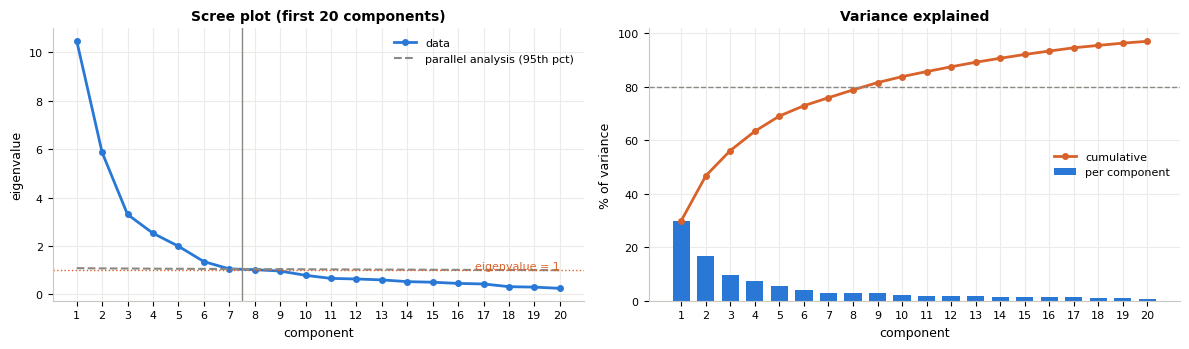

In [6]:
figures["scree_variance"] = plots.scree_plot(result)
display(figures["scree_variance"]); plt.close(figures["scree_variance"])

**What the figure shows.** *Left (scree plot):* the eigenvalue of each component against the two retention benchmarks. The first component has an eigenvalue of 10.5 and the second 5.9; the curve then drops steeply and flattens after about the seventh component. The dotted line marks the Kaiser threshold (eigenvalue = 1) and the dashed line marks the 95th percentile of eigenvalues from permuted data (parallel analysis, about 1.04–1.08). PC7 (1.048) lies just above the parallel-analysis line and PC8 (1.016) lies below it, which fixes the cut-off at seven components (the vertical line); the Kaiser rule alone would keep eight. *Right (variance explained):* the bars give the share of variance per component (PC1 30.0 %, PC2 16.8 %, PC3 9.4 %, PC4 7.2 %) and the line gives the cumulative share, which reaches 75.9 % at seven components and passes 80 % only at PC9. The figure therefore justifies keeping seven components and shows that a small number of components summarise most of the 35 variables, while the long tail means that no short summary captures everything.

## Step 4 · Interpretation of the components from their loadings

**Method.** For standardised data the **loading** of a variable on a component equals the correlation between that variable and the component's scores (−1 to +1); a large positive or negative loading means that the variable moves with the component. A variable's **contribution** to a component is its squared eigenvector weight, and the contributions of all variables to one component sum to 100 %. The sign of a component is arbitrary, so every component was oriented so that its largest-magnitude loading is positive. To interpret the components, the variable definitions of the data dictionary were used: variables ending in *Mean*, *Max*, *Min* or *Standard_Deviation* summarise the **whole record of a site** (its long-term climatology); `SSTA`, `TSA` and `Temperature_Kelvin` are the **weekly value at the time of sampling**; the `*_DHW` variables accumulate the **previous 12 weeks**; and the `*_Frequency` variables count anomalies over the **previous 52 weeks**.

**Results.** The components split almost exactly along the line between long-term climatology and recent conditions:

| Component | Variance | Interpretation | Strongest loadings |
|---|:-:|---|---|
| **PC1** | 30 % | **Long-term heat-stress history of the site**: how often, how strongly and how variably the site has been heat-stressed over the record | `SSTA_DHW_Standard_Deviation` +0.94, `SSTA_DHWMean` +0.90, `SSTA_DHWMax` +0.87, `SSTA_FrequencyMean` +0.85, `TSA_DHW_Standard_Deviation` +0.82; also `Turbidity` +0.52 |
| **PC2** | 17 % | **Typical thermal regime**: warm, thermally stable water (high) versus cooler water with a large seasonal swing (low) | `TSA_Mean` +0.91, `Temperature_Minimum` +0.88, `TSA_Minimum` +0.85, `Temperature_Mean` +0.78; `Temperature_Kelvin_Standard_Deviation` −0.86 |
| **PC3** | 9 % | **Heat stress at the time of the survey**: warm water with positive anomalies and recent degree heating weeks, in calm wind | `Temperature_Kelvin` +0.84, `TSA` +0.80, `SSTA` +0.63, `SSTA_DHW` +0.58, `TSA_DHW` +0.54; `Windspeed` −0.40 |
| **PC4** | 7 % | **Repeated heat stress over the past year, relative to a cooler normal**: frequent anomalies and accumulated DHW at sites with lower typical SST and clearer water | `TSA_Frequency` +0.61, `TSA_DHW` +0.50, `SSTA_DHW` +0.46, `SSTA_Frequency` +0.46, `Windspeed` +0.45; `ClimSST` −0.54, `Temperature_Maximum` −0.51, `Turbidity` −0.37 |
| **PC5** | 6 % | Variable anomaly frequency (high) versus extreme maximum anomalies (low), with distance to shore on the low side (less clear-cut) | `SSTA_Frequency_Standard_Deviation` +0.58, `SSTA_FrequencyMax` +0.57; `TSA_Maximum` −0.58, `SSTA_Maximum` −0.50, `Distance_to_Shore` −0.35 |

Further findings from the loadings:
- Degree heating weeks and anomaly frequency make up 76 % of PC1 and nearly half of PC4; PC2 is just over half SST and TSA variables (the "typical temperature" variables). The thermal variables dominate because there are 30 of them; this is a property of the data and not evidence that temperature is the most important factor.
- Turbidity, depth, distance to shore, cyclone frequency and wind do not form a major pattern of their own in components 1 to 5 (each contributes under 10 % to any of them; wind and turbidity reach 8 % and 6 % of PC4). They are largely independent of the thermal block and appear mainly in PC7, where depth alone accounts for 54 % of the component.


**Loading convention.** The original scaled-eigenvector formula is preserved for numerical comparability. Since preprocessing uses population SD, these loadings differ from exact sample correlations by the negligible factor sqrt(n/(n−1)). The saved model itself is sign-oriented, so its `transform` reproduces the exported scores.

**Loadings and contributions.** The loading and contribution of every variable were computed for the retained components, and the components were oriented as described above.

In [7]:
display(interpret_components(result, SETTINGS["n_interpret"]))

,variance_percent,leading_families,strongest_variables
component,,,
PC1,29.96,Degree heating weeks (DHW): 42.6%; Anomaly fre...,SSTA_DHW_Standard_Deviation (+0.94); SSTA_DHWM...
PC2,16.76,TSA (thermal stress anomaly): 27.2%; Sea surfa...,TSA_Mean (+0.91); Temperature_Minimum (+0.88);...
PC3,9.43,Sea surface temperature (SST): 26.7%; Degree h...,Temperature_Kelvin (+0.84); TSA (+0.80); SSTA ...
PC4,7.208,Sea surface temperature (SST): 32.5%; Anomaly ...,TSA_Frequency (+0.61); ClimSST (-0.54); Temper...
PC5,5.675,Anomaly frequency: 36.7%; SSTA (SST anomaly): ...,SSTA_Frequency_Standard_Deviation (+0.58); TSA...


**Loadings heatmap.** The loadings of all variables on the retained components, with the variables ordered by family.

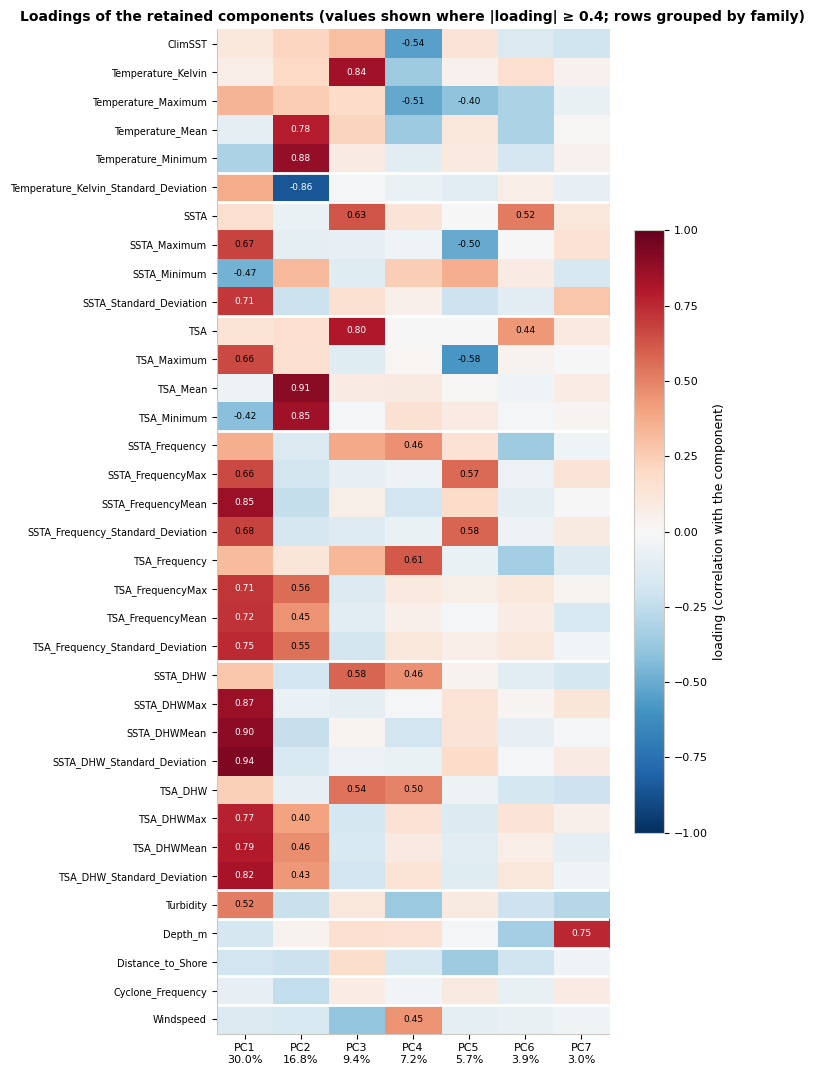

In [8]:
figures["loadings"] = plots.loading_heatmap(result)
display(figures["loadings"]); plt.close(figures["loadings"])

**What the figure shows.** The heatmap lists the loading (correlation with the component) of every variable on each retained component, with the variables grouped by environmental family and values printed where |loading| ≥ 0.4. Red cells move with the component and blue cells move against it. Each column has its own block of strong cells: PC1 is dominated by the long-term degree-heating-week and anomaly-frequency variables, PC2 by the typical-temperature variables (positive) against the seasonal temperature swing (negative), PC3 by the weekly temperature and anomaly values at the time of sampling, and PC4 by recent anomaly frequency and accumulated degree heating weeks together with a negative loading on typical sea-surface temperature. The figure shows that the components are not arbitrary mixtures: each is carried by a coherent group of related variables, which is what allows them to be named in the table above. Components 6 and 7 have few strong loadings and are harder to interpret.

**Strongest variables.** The variables with the largest absolute loadings on each of the first five components.

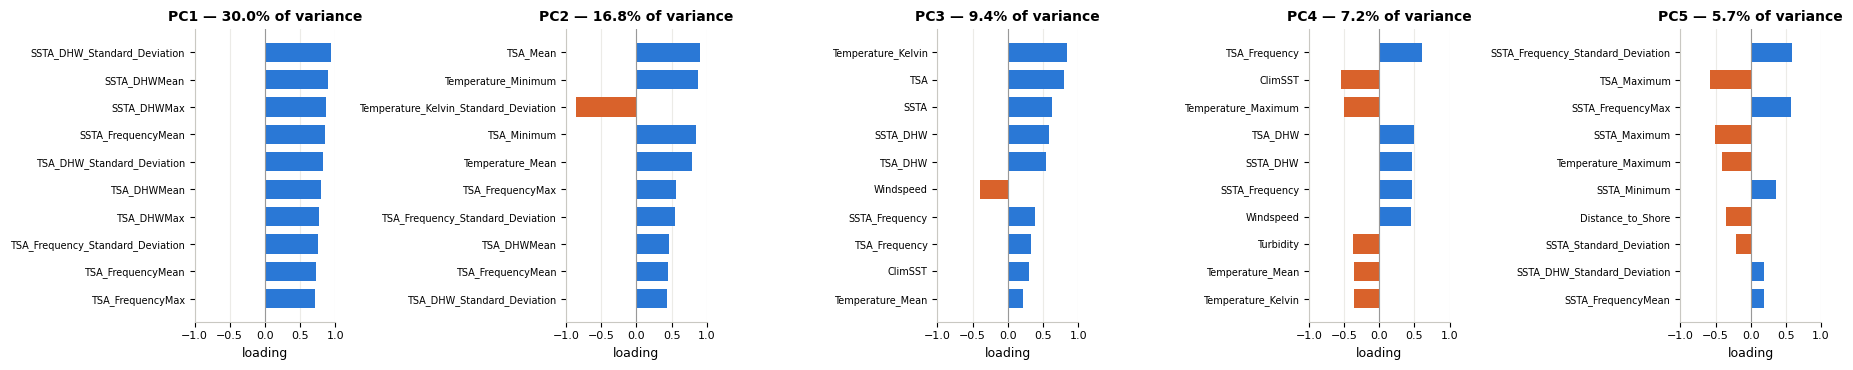

In [9]:
figures["strongest_loadings"] = plots.strongest_loadings(result, SETTINGS["n_interpret"])
display(figures["strongest_loadings"]); plt.close(figures["strongest_loadings"])

**What the figure shows.** For each of the first five components, the ten variables with the largest absolute loadings are drawn as horizontal bars (blue positive, red negative; the axis runs from −1 to +1). The bars confirm the interpretation of the heatmap with the actual values: PC1 reaches loadings of about +0.9 on long-term heat-stress variability and degree heating weeks, PC2 +0.91 on mean temperature anomaly and −0.86 on temperature variability, PC3 +0.84 on the temperature at the time of the survey, and PC4 loads positively on the recent anomaly frequency and degree heating weeks and negatively on the typical sea-surface temperature. Only a few variables per component carry loadings above 0.7, and the leading variables of different components differ, so each component describes a distinct aspect of the environment rather than repeating the same signal.

**Families.** The share of each component's contributions that comes from each environmental family.

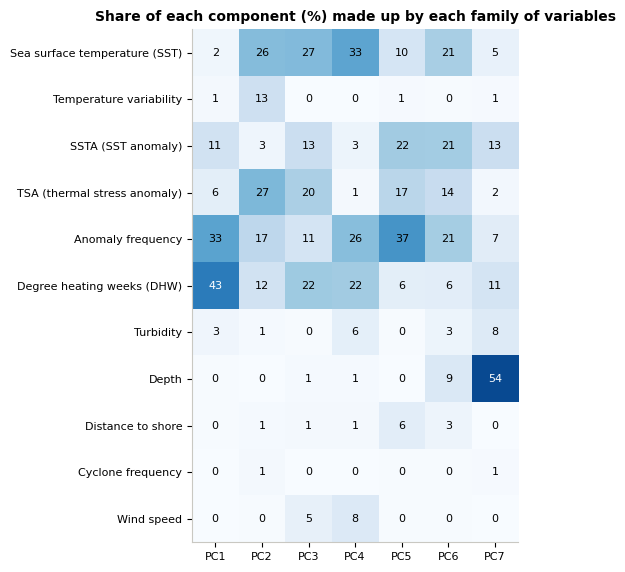

In [10]:
figures["family_contributions"] = plots.family_contributions(result)
display(figures["family_contributions"]); plt.close(figures["family_contributions"])

**What the figure shows.** The heatmap gives, for each retained component, the percentage of its total contribution that comes from each family of variables (each column sums to 100). It answers a different question from the loading plots: not which single variable is strongest, but which kind of environmental information the component is made of. Degree heating weeks and anomaly frequency make up most of PC1 (76 %) and nearly half of PC4, and the typical-temperature variables make up just over half of PC2. Non-thermal families (turbidity, depth, distance to shore, cyclones, wind) never contribute more than about 10 % to any of the first five components. This shows that the PCA is dominated by the thermal block, which holds 30 of the 35 variables; the figure describes the structure of the data and is not evidence that temperature is the most important factor for bleaching.

**Text summary.** A printed list of the main families and variables of each component.

In [11]:
display(result["families"].value_counts().rename("input_count").to_frame())

,input_count
family,
Anomaly frequency,8
Degree heating weeks (DHW),8
Sea surface temperature (SST),5
SSTA (SST anomaly),4
TSA (thermal stress anomaly),4
Distance to shore,1
Turbidity,1
Cyclone frequency,1
Depth,1


## Step 5 · Association of the components with bleaching severity

**Method.** The component scores were compared between the three bleaching groups. With about 23,000 samples even trivial differences give very small p-values, so the comparison was judged mainly on **effect size**:
- **Cliff's δ = 2·AUC − 1**, where the AUC is the probability that a randomly chosen High sample has a higher component score than a randomly chosen Low sample (0.5 means no separation). δ runs from −1 to +1 and is rank-based, so it is robust to skewed scores and outliers. The conventional guide is |δ| < 0.15 negligible, 0.15 to 0.33 small, 0.33 to 0.47 medium and above 0.47 large. δ was the headline measure because Step 9 uses the same rank statistic to control for data source;
- **Cohen's d**: the difference between the High and Low means divided by the pooled standard deviation (0.2 small, 0.5 medium, 0.8 large). It is the parametric counterpart of δ and assumes roughly symmetric distributions of similar spread, so it was reported next to δ as a check (Step 6 gives it with a confidence interval and an adjusted p-value);
- **Spearman ρ** between the score and the continuous bleaching percentage, which describes the gradient across the groups;
- **Kernel density estimates (KDE)** of the scores of each group. Each curve integrates to 1, so the unequal group sizes do not affect the comparison.

Medians and rank-based statistics were used because the groups are unbalanced and the scores are not normally distributed.

**Results.**
- **The two largest components barely separated the groups.** PC1 (30 % of the variance) had a negligible effect (δ = +0.03, with the Moderate group lowest rather than a steady rise) and PC2 (17 %) a small one (δ = −0.16). Together they cover 47 % of the environmental variation, yet in the PC1–PC2 plot the three groups lie almost on top of each other. **The largest patterns of environmental variation are not the patterns that matter most for bleaching.**
- **PC3 and PC4 separated the groups with a medium effect**: δ = +0.44 and +0.47 and AUC ≈ 0.72 to 0.74, i.e. a randomly chosen High sample scored higher than a randomly chosen Low sample about 72 to 74 % of the time. For both components the median rose steadily from Low to Moderate to High (PC3: −0.32, 0.75, 0.97; PC4: −0.21, 0.35, 1.25).
- **Cohen's d led to the same conclusion**: d = 0.82 for PC3 and 0.86 for PC4 (large), −0.22 for PC2 and −0.27 for PC5 (small) and 0.05 for PC1 (negligible). For PC3 and PC4 the AUC implied by d under normality (about 0.72 to 0.73) matches the observed AUC (0.72 to 0.74), so these two summaries are consistent here; this does not establish distribution-free inference. The two measures differ most for PC5 (d = −0.27 against δ = −0.11), where the mean difference is more sensitive to the shape of the distribution than the rank-based δ.
- **The density curves show the same pattern.** The curves of PC3 and PC4 shift to the right from Low through Moderate to High but overlap heavily, whereas the curves of PC1 and PC2 have several peaks and their medians do not rise steadily with severity.
- Higher scores on PC3 and PC4 correspond to more heat stress at the time of the survey and over the preceding year (Step 4). Together they hold only 17 % of the variance.
- The separation was a **gradient with heavy overlap**, not a set of distinct clusters: in the PC3–PC4 plot the High group lies towards the upper right but is mixed with Low and Moderate samples. The correlation between each score and the continuous bleaching percentage was modest (Spearman ρ = 0.32 for PC3 and 0.22 for PC4), so the environment alone does not determine the bleaching level.

**Group comparison table.** The effect sizes (Cliff's δ and Cohen's d) and the Spearman correlation of every retained component, with the medians of each group.

In [12]:
tables = analysis_tables(samples, X, result, SETTINGS["n_interpret"])
group_table = tables["pca_group_separation"]
display(group_table)

,variance_%,median_Low,median_Moderate,median_High,AUC_high_vs_low,cliffs_delta,cohens_d,epsilon2,spearman_with_bleaching_%,strength
component,,,,,,,,,,
PC1,29.96,0.1167,-0.8479,0.351,0.5143,0.02852,0.0549,0.01126,-0.1347,negligible
PC2,16.76,0.6667,-0.4075,0.09252,0.4224,-0.1552,-0.2189,0.03115,-0.1942,small
PC3,9.43,-0.3223,0.7476,0.9685,0.7197,0.4395,0.8163,0.07939,0.318,medium
PC4,7.208,-0.2079,0.3507,1.249,0.7356,0.4712,0.8627,0.06345,0.216,medium
PC5,5.675,0.1753,-0.2233,0.01772,0.4462,-0.1076,-0.2679,0.02157,-0.2225,negligible
PC6,3.858,0.05725,-0.09827,-0.2564,0.4151,-0.1697,-0.291,0.009379,-0.092,small
PC7,2.995,-0.02678,0.182,-0.1476,0.4947,-0.01053,0.03966,0.007446,0.08042,negligible


**Score plots.** The samples plotted on pairs of components and coloured by bleaching group.

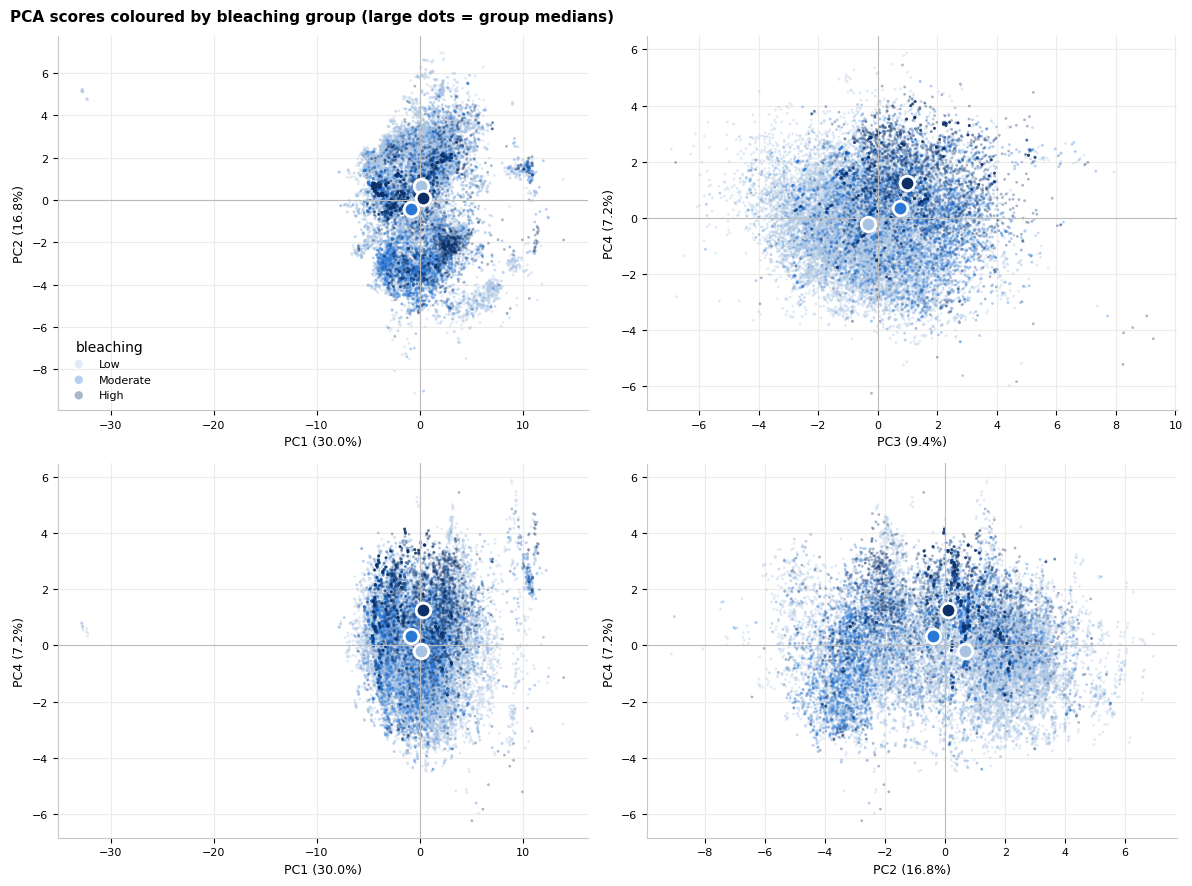

In [13]:
figures["score_groups"] = plots.score_plots(result, group_table, samples.Bleaching_Group.to_numpy())
display(figures["score_groups"]); plt.close(figures["score_groups"])

**What the figure shows.** Each point is one sample placed by its scores on two components, coloured by bleaching group (light = Low, mid = Moderate, dark = High), and the large dots are the group medians. The panels pair PC1 with PC2, PC3 with PC4, and each of PC1 and PC2 with PC4. *PC1 vs PC2:* the three medians lie close together near the origin and are not ordered by severity (the Moderate median is lowest on PC2 and the Low median highest), so these two components, which carry long-term climate and geography, do not separate the groups; the cloud is structured into regional clusters rather than by bleaching. *PC3 vs PC4 and the PC4 panels:* the medians move in order from Low to Moderate to High, towards higher PC3 and especially higher PC4, and in the PC1 and PC2 panels the medians are stacked along the PC4 axis but barely move along PC1 or PC2. The shift is a shift of the centre of each group: the point clouds overlap heavily, so a sample's position does not identify its bleaching group. The plot is a visual check only (the points are strongly overplotted and High samples are a minority); the effect sizes and tests below give the quantitative evidence. A small set of samples far out on PC1 (near −32) and a cluster near +10 to +12 do not affect the medians.

**Score densities.** Kernel density estimate (KDE) of each interpreted component within each bleaching group. Each curve integrates to 1; dashed lines mark the group medians; the titles give Cohen's d and Cliff's δ.

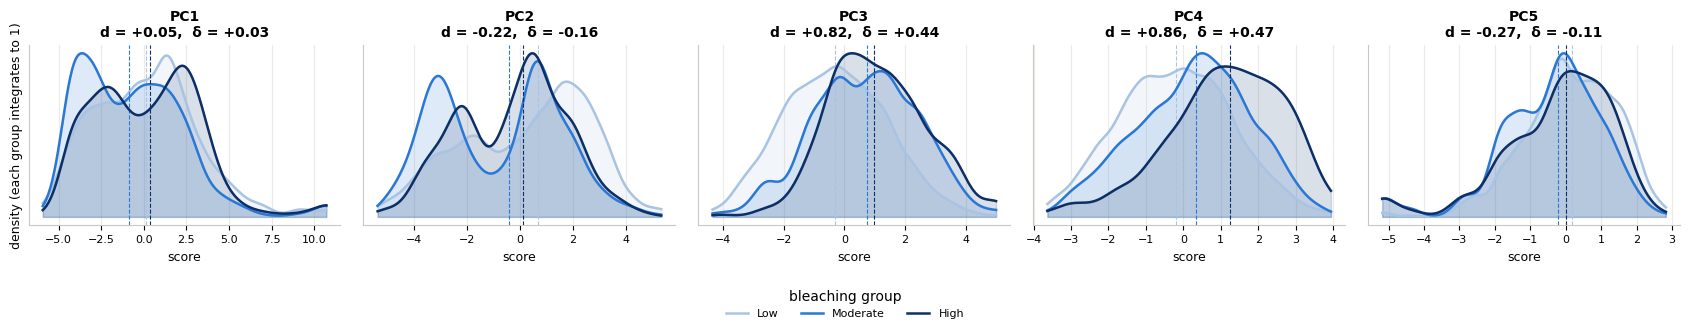

In [14]:
figures["score_densities"] = plots.score_densities(result, group_table, samples.Bleaching_Group.to_numpy(), SETTINGS["n_interpret"])
display(figures["score_densities"]); plt.close(figures["score_densities"])

**What the figure shows.** Each panel is the distribution (kernel density) of the scores of one component, drawn separately for the Low, Moderate and High groups; dashed lines mark the group medians, and the panel title gives Cohen's d and Cliff's δ for High versus Low. For PC1 the three curves nearly coincide (d = +0.06, δ = +0.03), and for PC2 and PC5 the shift is small and in the negative direction (d = −0.22 and −0.27). For PC3 (d = +0.82, δ = +0.44) and PC4 (d = +0.86, δ = +0.47) the High curve is clearly displaced to the right of the Low curve, with the Moderate curve in between. The curves still overlap over most of their range: bleaching is associated with a shift in the distribution of these components, not with a separate range of values. This view shows what a medium effect size looks like and that the shift is a gradual, ordered one across the three groups.

**Components ranked by separation.** Cliff's δ of every retained component as a bar chart.

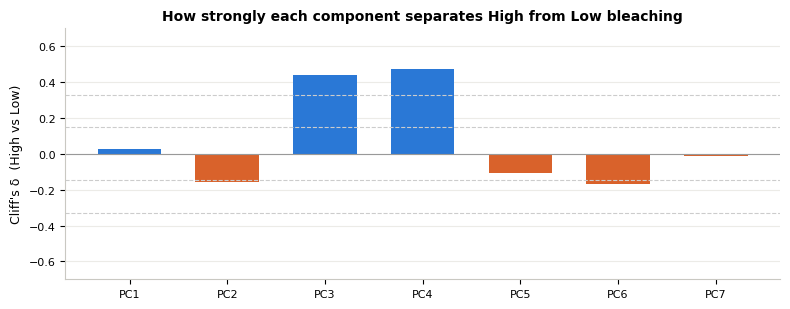

In [15]:
figures["component_delta"] = plots.component_delta(group_table)
display(figures["component_delta"]); plt.close(figures["component_delta"])

**What the figure shows.** Cliff's δ (High versus Low) of each retained component as a bar, with dashed reference lines at ±0.147, ±0.33 that mark the boundaries between negligible, small, medium and large effects. Two components pass the medium threshold: PC3 (δ = +0.44) and PC4 (δ = +0.47), both positive, i.e. High samples tend to have higher scores. PC2 (−0.16) and PC6 (−0.17) are small and negative, and PC1 (+0.03), PC5 (−0.11) and PC7 (−0.01) are negligible. PC1, the component with the most variance, is therefore not the one most related to bleaching; the variance a component explains and its association with the outcome are different things, and the relevant information lies in the third and fourth components.

## Step 6 · Information about bleaching retained by the components

**Method.** To quantify how much of the High-versus-Low difference is retained after the dimension reduction, only statistical tests were used (no predictive model). Samples with High bleaching were compared with samples with Low bleaching as follows:
- a **Welch t-test** (which does not assume equal variances) on each retained component and, for comparison, on each original variable, reported with the mean difference, its 95 % confidence interval and Cohen's d (based on the sample-size-weighted pooled standard deviation);
- **Benjamini–Hochberg false-discovery-rate (BH-FDR)** adjustment of the p-values within each family of tests, so that testing many components or variables does not create false findings; a q-value below 0.05 was counted as significant;
- a **site-level repeat** of the Welch test on site means (the High samples of a site averaged and compared with the averaged Low samples of a site), because samples from the same site are not independent;
- **Hotelling's T² test** on all retained components together. Its squared Mahalanobis distance D² is a multivariate effect size, and the ratio D²(retained components) / D²(all variables) is the share of the High-versus-Low separation retained by the components. Because the PCA is a rotation of the variables, D² for all components equals D² for all variables.

With this many samples nearly every p-value is very small, so the effect sizes and confidence intervals, not only the q-values, were used to judge the results.

**Inference correction.** The original sample-level Welch/FDR and Hotelling outputs and independent-site Welch/FDR are preserved as nominal, legacy comparisons. There are 196 sites with both High and Low observations; a site can contribute to both vectors of site means. Averaging by site therefore does not justify independence between those vectors. The original claim that those p-values establish independence from repeated-site effects is withdrawn.

The additional audit resamples the union of sites, using the same sampled site weights for both groups and retaining all available High/Low site means. It reports the same difference of site means with a pointwise percentile 95% interval. It neither supplies multiplicity-adjusted p-values nor includes uncertainty from refitting PCA. Independence between sites remains an assumption. This is a correction to uncertainty, not a replacement estimand or a new research question. See [SciPy bootstrap documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html) and the [cluster bootstrap methodology](https://pmc.ncbi.nlm.nih.gov/articles/PMC7148287/).

The D² ratio measures compression of the observed group mean separation only; it is not a general measure of retained predictive information. Nominal p-values can underflow to zero numerically and should not be reported as exact zero probabilities. The current tables below provide effects, original tests, and corrected intervals separately.

,mean_high,mean_low,difference,ci95_low,ci95_high,cohens_d,...,df,p,site_level_d,site_level_p,q_bh,site_level_q_bh
variable,,,,,,,,,,,,,
PC1,0.2895,0.1111,0.1784,0.03492,0.3219,0.0549,...,"2,786",0.01483,0.2072,8.415e-14,0.0173,1.473e-13
PC2,-0.2952,0.2302,-0.5254,-0.6183,-0.4325,-0.2189,...,"3,053",4.629e-28,-0.1346,4.565e-08,8.1e-28,6.391e-08
PC3,1.108,-0.3083,1.417,1.342,1.492,0.8163,...,"2,825",1.271e-245,0.8012,7.519e-170,8.899e-245,5.263e-169
PC4,1.121,-0.2051,1.326,1.256,1.397,0.8627,...,"2,724",2.516e-241,0.8537,5.142e-163,8.807e-241,1.8e-162
PC5,-0.2316,0.1352,-0.3668,-0.4366,-0.2971,-0.2679,...,"2,590",1.777e-24,-0.03308,0.2414,2.487e-24,0.2414
PC6,-0.2742,0.06391,-0.3381,-0.39,-0.2862,-0.291,...,"2,768",2.262e-36,-0.1501,7.743e-08,5.278e-36,9.033e-08
PC7,-0.009274,-0.04949,0.04022,-0.009033,0.08947,0.03966,...,"2,647",0.1094,-0.2529,7.644e-18,0.1094,1.784e-17


,mean_high,mean_low,difference,ci95_low,ci95_high,cohens_d,...,df,p,site_level_d,site_level_p,q_bh,site_level_q_bh
variable,,,,,,,,,,,,,
TSA_DHW,0.9064,-0.1935,1.1,1.055,1.145,1.212,...,"2,622",0,1.293,2.917e-304,0,1.021e-302
SSTA_DHW,0.7347,-0.1535,0.8882,0.8456,0.9308,0.9277,...,"2,774",1.155e-286,1.053,2.566e-262,2.021e-285,4.49e-261
TSA_Frequency,0.6626,-0.1176,0.7802,0.7408,0.8197,0.8021,...,"2,945",4.39e-266,0.8655,1.359e-199,3.841e-265,1.586e-198
SSTA_Frequency,0.5996,-0.1122,0.7119,0.6697,0.754,0.7286,...,"2,824",3.305e-203,0.7836,3.473e-146,2.313e-202,3.039e-145
SSTA_Standard_Deviation,0.526,-0.1222,0.6481,0.616,0.6803,0.6473,...,"3,691",1.208e-285,0.5022,9.062e-100,1.41e-284,6.344e-99
TSA,0.3739,-0.09788,0.4718,0.4281,0.5155,0.4788,...,"2,780",1.68e-92,0.5185,8.844e-78,9.797e-92,5.159e-77
SSTA,0.3209,-0.07739,0.3983,0.3508,0.4457,0.4076,...,"2,648",4.547e-58,0.4666,4.615e-53,2.274e-57,2.308e-52
Temperature_Kelvin,0.2434,-0.07698,0.3203,0.2743,0.3664,0.3204,...,"2,721",4.414e-41,0.3593,1.572e-33,1.545e-40,6.875e-33
Depth_m,0.2279,-0.08766,0.3156,0.2713,0.3599,0.32,...,"2,758",6.92e-43,0.1138,2.61e-05,3.028e-42,5.709e-05


,n_features,mahalanobis_sq,F,df1,df2,p,share_of_all_variables_D2
inputs,,,,,,,
PC1–PC2,2,0.05034,48.56,2,19080,9.195e-22,0.0137
PC1–PC7 (retained),7,1.854,511,7,19075,0,0.5047
all 35 original variables,35,3.674,202.2,35,19047,0,1


,difference_of_site_means,cluster_ci95_low,cluster_ci95_high,sites_high,sites_low,sites_both,bootstrap_resamples
variable,,,,,,,
PC1,0.6642,0.4833,0.8329,1577,7370,196,1000
PC2,-0.3435,-0.4631,-0.2112,1577,7370,196,1000
PC3,1.387,1.297,1.481,1577,7370,196,1000
PC4,1.307,1.224,1.393,1577,7370,196,1000
PC5,-0.04205,-0.1124,0.02635,1577,7370,196,1000
PC6,-0.1698,-0.2306,-0.106,1577,7370,196,1000
PC7,-0.2404,-0.2911,-0.19,1577,7370,196,1000


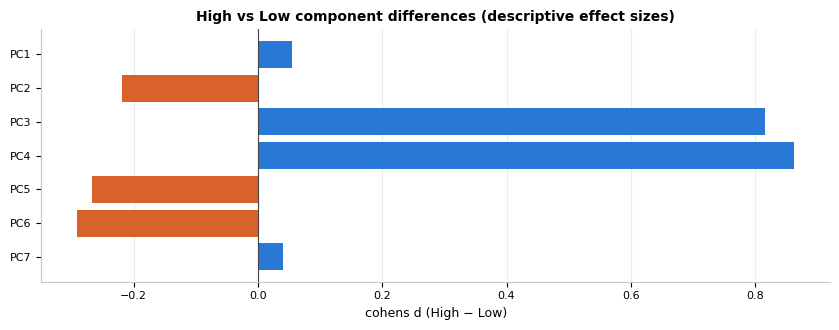

In [16]:
# Original nominal tests remain available for a transparent before/after comparison.
display(tables["welch_tests_components"])
display(tables["welch_tests_variables"].sort_values("cohens_d", key=abs, ascending=False).head(10))
display(tables["hotelling_high_vs_low"])
comparison_columns = {name: retained_scores[name].to_numpy() for name in retained_scores}
comparison_columns.update({name: X[name].to_numpy() for name in X})
tables["site_cluster_intervals"] = site_cluster_intervals(
    comparison_columns, samples.Bleaching_Group.to_numpy(), samples.Site_ID.to_numpy(),
    resamples=SETTINGS["bootstrap_resamples"], seed=SETTINGS["seed"],
)
display(tables["site_cluster_intervals"].loc[list(retained_scores)])
figures["component_cohen_d"] = plots.effect_sizes(tables["welch_tests_components"], title="High vs Low component differences (descriptive effect sizes)")
display(figures["component_cohen_d"]); plt.close(figures["component_cohen_d"])

**Reading the figure.** Signed, sample-size-weighted Cohen's d describes the High-minus-Low mean difference on each retained component. The figure shows effect magnitudes rather than treating legacy sample-level significance as confirmation. Use the site-cluster interval table for the corrected uncertainty audit.

## Step 7 · Preparation of the categorical interpretation

**Method.** The categorical columns were excluded from the PCA and are used here only to interpret it. Missing categories were labelled `Unknown`, the categorical features analysed in the next steps were selected (data source, ocean, realm, country, ecoregion and exposure; high-cardinality labels such as site name and reef identifier remain in the file but are not analysed), and a summary table of the data sources was built (samples, sites, share of High and Low samples, median bleaching and period covered). Source fits are compared with the same full-cohort solution; no redundant full-cohort refit is needed for the primary scores. Missing categories are labelled Unknown on a separate interpretation copy, leaving the loaded table unchanged.

**Results.** The data sources differed strongly in size and in how much bleaching they report, so they cannot be pooled naively:
- Reef Check (11,249 samples) and AGRRA (2,847) contained almost no High samples (111 and 0, i.e. about 1 % and 0 %).
- Donner (5,618 samples) reported bleaching most often: 30.5 % of its samples were High. **Donner supplied 1,715 of the 2,178 High samples (79 %).**
- FRRP, Kumagai and McClanahan supplied 122, 77 and 131 High samples. Safaie and the two smallest sources contributed too few samples to be analysed separately.

The pooled High-versus-Low comparisons are therefore partly comparisons between data sources, which motivates the within-source analysis of Step 9.

In [17]:
display(tables["data_source_summary"])

,samples,sites,pct_high,pct_low,median_bleaching,mean_bleaching,pct_depth_imputed,first_year,last_year,n_high,n_low
Data_Source,,,,,,,,,,,
Reef_Check,11249,3910,0.9868,94.18,0,2.526,0,1998,2019,111,10594
Donner,5618,3238,30.53,37.56,30.5,34.79,27.96,1998,2011,1715,2110
AGRRA,2847,603,0,89.53,0.91,3.313,0.9835,1998,2016,0,2549
FRRP,2394,2299,5.096,49.29,10.26,15.31,0,2005,2016,122,1180
Kumagai,660,649,11.67,61.97,5.5,17.46,0,2004,2016,77,409
McClanahan,218,192,60.09,8.716,62.86,57.05,0,2016,2016,131,19
Safaie,74,41,24.32,59.46,5,23.24,0,1998,2011,18,44
Nuryana,5,5,0,0,35,30.9,100,2015,2016,0,0
Setiawan,4,4,100,0,65.5,66,100,2016,2016,4,0


## Step 8 · Relation of the components to the categorical features

**Method.** For each categorical feature and each component, **ω²** is the share of the component's variance that differs *between* the categories. It is a bias-corrected version of η², so that features with many levels are not favoured by chance; categories with fewer than 50 samples were pooled into "Other". The last row of the table is the reference: the share explained by the **bleaching group**, the quantity the analysis tries to explain.

**Results.**
- **The largest components were geographic.** Country and ecoregion explained 48 % and 48 % of PC1 and 75 % and 80 % of PC2 (and about 50 % of PC5), and realm and ocean explained 29 % and 22 % of PC1. These components describe *where* a site is (its long-term climate), in agreement with the reading of the loadings in Step 4.
- **The bleaching group explained very little of any component** (at most 8 % of PC3 and 6 % of PC4, and under 3 % of the rest). The component most tied to bleaching is not the one most tied to geography.
- **Data source explained a moderate share of several components** (29 % of PC2, 14 % of PC3, 13 % of PC5, 12 % of PC4 and 9 % of PC1). For PC3 and PC4 the data source explained *more* of the variance than the bleaching group, so part of the PC3 and PC4 pattern is a source effect; Step 9 measures how much.
- **Exposure explained little** (at most 10 % of PC1, 7 % of PC5, 2 % of PC3 and under 1 % of PC4), so it is not a major environmental axis in this dataset.
- Country and ecoregion have many levels and partly coincide with data source (a source often works in a few regions); ω² corrects for the number of levels but cannot separate these overlaps.

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
Data_Source,8.8,29.4,13.9,11.6,12.8,3.5,4.9
Ocean_Name,22.4,6,3.9,4.3,12.7,2.3,4.9
Realm_Name,28.8,14.7,4.9,5,12.4,8.1,7.1
Country_Name,48,74.7,24.2,34.1,49.8,21.6,23.6
Ecoregion_Name,48,79.5,20.5,40.5,47.8,20,21.8
Exposure,10,4.2,2,0.6,7.1,0.6,6.2
Bleaching_Group (reference),0.8,2.7,8.2,6.4,2.7,0.9,0.9


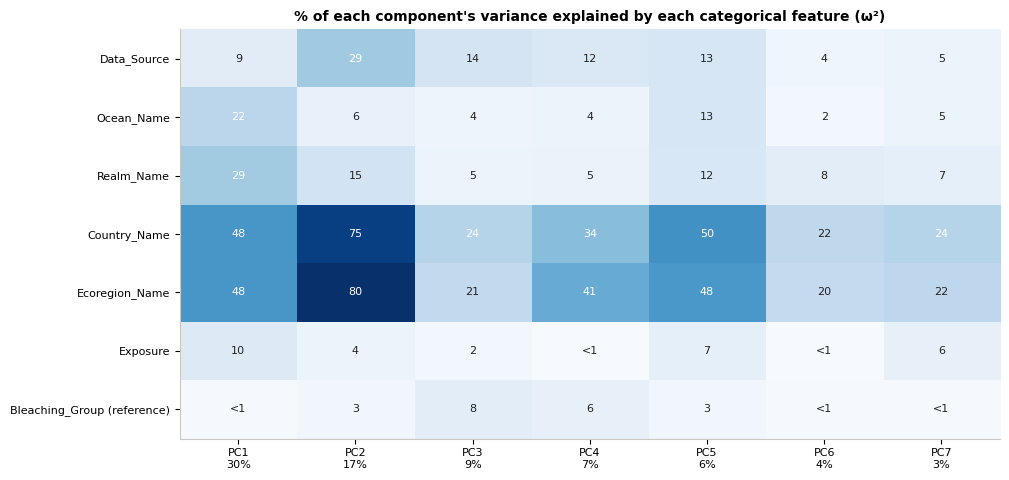

In [18]:
display(tables["categorical_omega2_by_component"].round(1))
figures["categorical_omega2"] = plots.categorical_heatmap(result, tables["categorical_omega2_by_component"])
display(figures["categorical_omega2"]); plt.close(figures["categorical_omega2"])

**What the figure shows.** The heatmap gives the percentage of each retained component's variance explained by each categorical feature (ω², corrected for the number of categories); the bottom row, bleaching group, is the reference. Country and ecoregion explain the most: 75 % and 80 % of PC2, about 48–50 % of PC1 and PC5, and 34 % and 41 % of PC4. The data source explains 29 % of PC2. This shows that PC1, PC2 and PC5 largely encode where a reef is (its region and the data source that surveyed it). In contrast, bleaching group explains only 8.2 % of PC3 and 6.4 % of PC4 and under 3 % of the other components; PC3 and PC4 are the components most related to bleaching and also the ones that are least tied to a location (country explains 24 % of PC3). The figure shows both what the components represent and why the pooled analysis has to be checked within data sources (next step).

## Step 9 · Control for data source: separation within each source

**Method.** A pooled association between a component and bleaching can arise only because the sources that report more bleaching also sit in different environments. To remove this, the High-versus-Low comparison of Step 5 (Cliff's δ) was repeated **inside each data source** and the within-source values were then combined into one **source-adjusted δ**, in which each source is weighted by its number of High × Low sample pairs (the stratified version of the AUC). Only sources with at least 30 High and 30 Low samples were analysed.

**Results.**
- **The heat-stress finding survived the control, but weaker.** Within every one of the four large sources (Reef Check, Donner, FRRP and Kumagai), High samples scored higher than Low samples on **both PC3 and PC4**: PC3 δ = 0.40, 0.22, 0.63 and 0.79, and PC4 δ = 0.44, 0.31, 0.55 and 0.42 respectively. The medians rose from Low to Moderate to High in each source.
- **The source-adjusted δ was 0.28 for PC3 and 0.35 for PC4**, compared with 0.44 and 0.47 pooled. The stratified estimates are smaller, but the comparison changes source eligibility and weighting as well as stratification. It does not isolate a causal fraction attributable to source. What remains is a **small-to-medium** effect, and the weakest source (Donner, which holds most of the High samples) has the smallest effect.
- **The large components remained unrelated to bleaching**: the adjusted δ was +0.12 for PC1, −0.06 for PC2 and +0.09 for PC5. Their pooled values (+0.03, −0.16 and −0.11) changed sign or size with source, so they are not reliably related to bleaching.
- The sources differ in their *baseline* on PC3 (for example the Low group of Kumagai lies near −1.6 while the Low group of FRRP lies near +0.8), so raw scores are not comparable between sources. Within-source comparisons are therefore the fair test.

**Within-source table.** Cliff's δ of every component within each source, together with the pooled and source-adjusted values.

In [19]:
display(tables["within_source_component_delta"])

,n_high,n_low,PC1,PC2,PC3,PC4,PC5
Reef_Check,111,1.059e+04,-0.04876,-0.08618,0.4029,0.437,-0.06027
Donner,"1,715","2,110",0.1646,-0.04895,0.2203,0.3112,0.1398
FRRP,122,"1,180",0.3427,-0.1235,0.6302,0.5509,0.05168
Kumagai,77,409,0.1198,0.3203,0.7906,0.4171,0.2215
POOLED (all samples),NaN,NaN,0.02852,-0.1552,0.4395,0.4712,-0.1076
SOURCE-ADJUSTED,NaN,NaN,0.119,-0.05758,0.279,0.3486,0.0904


**Heatmap of within-source δ.** The same values as a heatmap, with the number of High and Low samples of each source.

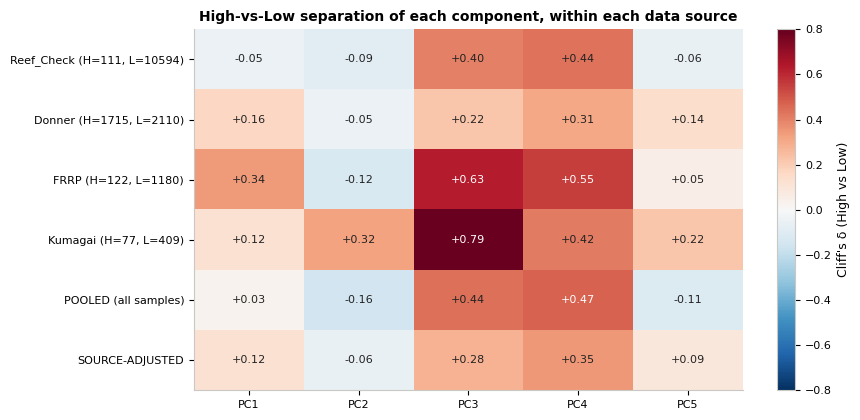

In [20]:
figures["source_delta"] = plots.source_delta_heatmap(tables["within_source_component_delta"], tables["within_source_only"], SETTINGS["n_interpret"])
display(figures["source_delta"]); plt.close(figures["source_delta"])

**What the figure shows.** The heatmap gives Cliff's δ (High versus Low) of each of the first five components computed inside each data source, with the pooled value and the source-adjusted value in the bottom rows (red = High scores higher, blue = lower). The columns PC3 and PC4 are red in every source (δ = 0.40, 0.22, 0.63 and 0.79 on PC3 and 0.44, 0.31, 0.55 and 0.42 on PC4, for Reef Check, Donner, FRRP and Kumagai), so the heat-stress pattern is not produced by one source. PC1, PC2 and PC5 change sign or stay near zero from source to source. The source-adjusted values (PC3 0.28, PC4 0.35) are lower than the pooled values (0.44 and 0.47), showing sensitivity to source stratification and weighting, without isolating a causal source effect. The weakest within-source effect is in Donner, which holds most of the High samples, so the conclusion is of a consistent but small-to-medium association, not a large one.

**Distributions inside each source.** PC3 and PC4 by bleaching group within each large source.

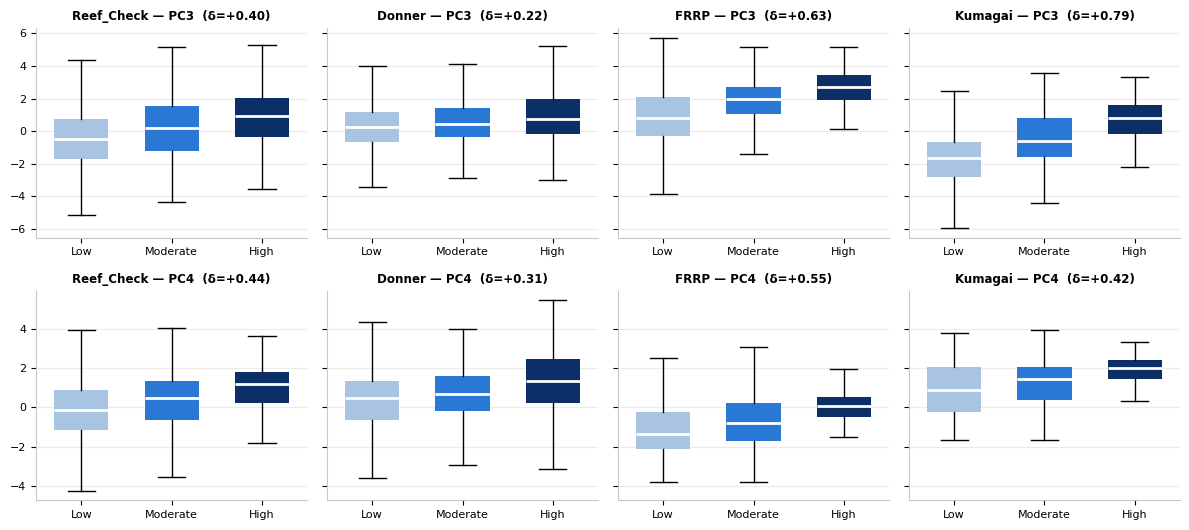

In [21]:
figures["within_source_distributions"] = plots.source_distributions(samples, scores, tables["within_source_only"])
display(figures["within_source_distributions"]); plt.close(figures["within_source_distributions"])

**What the figure shows.** For each of the four large sources, box plots of the PC3 scores (top row) and PC4 scores (bottom row) in the Low, Moderate and High groups (outliers not drawn; the white line is the median), with the within-source δ in the panel title. In every source the boxes move upwards from Low to Moderate to High, but the boxes of neighbouring groups overlap. The shift is largest in Kumagai and FRRP on PC3 and in FRRP on PC4, and smallest in Donner. The figure shows the raw distributions behind the heatmap of the previous figure: the association with heat stress is visible inside each source without pooling, which supports using PC3 and PC4 as the heat-stress components, while the overlap shows that the components describe tendencies and do not classify individual samples.

## Step 10 · Stability of the PCA structure across data sources

**Method.** The PCA was refitted separately on each large data source (at least 800 samples), and the loadings of each fit were compared with the loadings of the full-data PCA using the **congruence coefficient** (1.00 means an identical component; a low value means a different component; the sign is ignored). A label "(as PCk)" means that the full-data component is best matched by the k-th component of the within-source fit, i.e. the order of the components changed. If the structure is environmental it should reappear in every source; if it is a survey artefact it should not.

**Results.**
- **The main thermal structure reappeared in every large source.** Refitting the PCA on Reef Check alone reproduced all five components (congruence 0.85 to 0.98). In Donner, PC1 (0.97) and PC2 (0.81) were close to the full solution, and PC3 and PC4 were present but in swapped order, with congruence 0.64 to 0.74. In AGRRA, PC1 to PC3 matched (0.76 to 0.88) and PC4 was weaker (0.51).
- **FRRP, the smallest of the four, matched less well** (PC1 0.88 and the other components 0.17 to 0.87, with reordering), as expected from 2,394 samples in a narrow set of regions. The structure was clearest where the sample is large and spread over many regions.

The source fits support recurring thermal structure while also showing source-specific variation; congruence alone cannot rule out survey confounding. Matching uses the original independent best absolute-cosine match, so it is not constrained to a one-to-one assignment. These refits use globally transformed inputs for descriptive comparability, not fold-fitted predictive evaluation.

In [22]:
tables["source_loading_congruence"] = compare_sources(X, samples, tables["data_source_summary"].index[:4], SETTINGS["n_interpret"], SETTINGS["seed"])
display(tables["source_loading_congruence"].pivot(index="source", columns="component", values="congruence").round(3))

component,PC1,PC2,PC3,PC4,PC5
source,,,,,
AGRRA,0.876,0.763,0.844,0.511,0.653
Donner,0.974,0.813,0.727,0.637,0.65
FRRP,0.883,0.473,0.873,0.767,0.17
Reef_Check,0.976,0.847,0.867,0.906,0.886


## Step 11 · Variable-level contrasts and environmental families

The older PCA notebook compared each original transformed environmental variable between High and Low samples using AUC, group means, and a difference divided by the equally weighted group variances. This convention differs from the sample-size-weighted pooled SD used by the main notebook's Cohen's d. Both are preserved and explicitly labelled rather than silently made interchangeable. These are standardised, power-transformed environmental values, not raw-unit effects.

Kruskal–Wallis epsilon-squared across all three groups is retained in the component association table. The family-average variable effects below are descriptive summaries, not independent tests or equal weighting of families in the primary PCA.

,family,legacy_unweighted_d,AUC_high_vs_low,mean_low,mean_moderate,mean_high
variable,,,,,,
TSA_DHW,Degree heating weeks (DHW),1.147,0.7756,-0.1935,0.3253,0.9064
SSTA_DHW,Degree heating weeks (DHW),0.9295,0.7502,-0.1535,0.2495,0.7347
TSA_Frequency,Anomaly frequency,0.8395,0.7259,-0.1176,0.1366,0.6626
SSTA_Standard_Deviation,SSTA (SST anomaly),0.7434,0.7683,-0.1222,0.2307,0.526
SSTA_Frequency,Anomaly frequency,0.7407,0.703,-0.1122,0.1484,0.5996
TSA,TSA (thermal stress anomaly),0.4806,0.6228,-0.09788,0.2108,0.3739
SSTA,SSTA (SST anomaly),0.3902,0.6157,-0.07739,0.1529,0.3209
Depth_m,Depth,0.319,0.5826,-0.08766,0.2472,0.2279
Temperature_Kelvin,Sea surface temperature (SST),0.3155,0.5721,-0.07698,0.1935,0.2434


,mean,min,max,count
family,,,,
Anomaly frequency,0.0786,-0.2189,0.8395,8
Cyclone frequency,-0.05594,-0.05594,-0.05594,1
Degree heating weeks (DHW),0.2009,-0.1831,1.147,8
Depth,0.319,0.319,0.319,1
Distance to shore,0.187,0.187,0.187,1
SSTA (SST anomaly),0.291,-0.009517,0.7434,4
Sea surface temperature (SST),-0.08291,-0.2876,0.3155,5
TSA (thermal stress anomaly),0.07465,-0.1792,0.4806,4
Temperature variability,0.1131,0.1131,0.1131,1


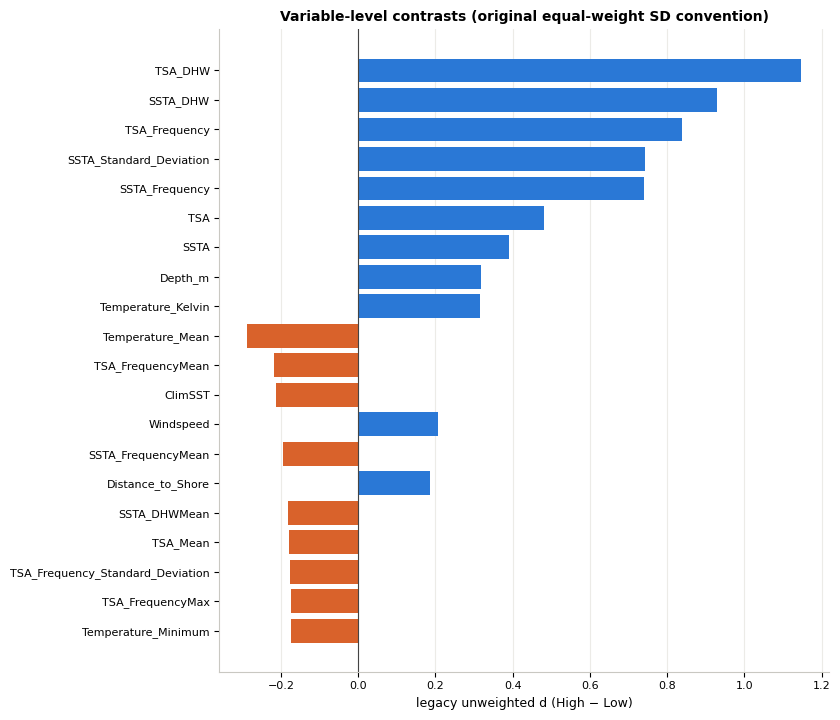

In [23]:
display(tables["variable_high_vs_low"].head(15))
display(tables["variable_family_effects"])
figures["variable_effects"] = plots.effect_sizes(tables["variable_high_vs_low"], column="legacy_unweighted_d", title="Variable-level contrasts (original equal-weight SD convention)", top=20)
display(figures["variable_effects"]); plt.close(figures["variable_effects"])

## Step 12 · How much predictive information survives compression?

The older notebook compared multinomial logistic regression on PC1–PC2, retained components, and all inputs using five site-disjoint folds and balanced class weights. This remains a diagnostic of compression, separate from descriptive PCA.

**Legacy versus corrected evaluation.** The original split sites only after preprocessing and PCA had been fitted globally, so its held-out feature representation used test-set information. That diagnostic is retained under `legacy_global_fit`. Under `fold_fitted`, original-unit measurements with their missing values are recovered from the raw source through the existing cleaning functions; medians, skew decisions, power parameters, scaling, and PCA are fitted inside each training fold, then applied to held-out sites. The study cohort, 35 named features, and chosen dimension remain fixed: this is conditional evaluation, not validation of the entire cohort-selection or component-retention procedure. Site-disjoint folds do not establish future-year or external-source generalisation.

In [24]:
if SETTINGS["run_prediction_check"]:
    cv_measurements = load_cv_measurements(ROOT, samples, list(X))
    tables["grouped_prediction"], tables["cv_fold_audit"] = grouped_prediction(
        X, retained_scores, samples, cv_measurements, folds=SETTINGS["cv_folds"], seed=SETTINGS["seed"])
    display(tables["grouped_prediction"])
    display(tables["cv_fold_audit"])

,mode,inputs,balanced_accuracy,macro_AUC,AUC_high_vs_low
0,legacy_global_fit,PC1–PC2,0.4516,0.6014,0.5797
1,legacy_global_fit,retained PCs,0.5774,0.7694,0.8417
2,legacy_global_fit,all variables,0.6232,0.81,0.8979
3,fold_fitted,PC1–PC2,0.4524,0.6014,0.5797
4,fold_fitted,retained PCs,0.5768,0.7691,0.8417
5,fold_fitted,all variables,0.624,0.8102,0.8981


,mode,fold,train_samples,test_samples,shared_sites
0,legacy_global_fit,1,18455,4614,0
1,legacy_global_fit,2,18455,4614,0
2,legacy_global_fit,3,18455,4614,0
3,legacy_global_fit,4,18455,4614,0
4,legacy_global_fit,5,18456,4613,0
5,fold_fitted,1,18455,4614,0
6,fold_fitted,2,18455,4614,0
7,fold_fitted,3,18455,4614,0
8,fold_fitted,4,18455,4614,0
9,fold_fitted,5,18456,4613,0


## Step 13 · Robustness and missing-depth sensitivity

Distinct checks from the older notebook are retained: twelve refits on random halves of sites; a sensitivity fit after pruning |Pearson r| ≥ 0.90 inputs; exclusion of observations with |retained score| > 10 for a separate refit; and comparisons involving imputed depth. None changes the primary dataset. Correlation pruning reduces repeated information but does not give each environmental family exactly equal weight. Congruence is sign-invariant and is reported on common variables; it is an exploratory stability check.

The missing-depth analysis compares imputed with measured-depth scores and repeats High-versus-Low contrasts among measured-depth observations. Because depth missingness is source-related, stability should be considered alongside the source and time results, not as proof of absence of bias.

In [25]:
tables["robustness_congruence"], robustness_summary = robustness_checks(X, samples, result, SETTINGS["n_interpret"], SETTINGS["seed"], SETTINGS["extreme_score"])
tables["depth_sensitivity"] = depth_sensitivity(samples, scores.iloc[:, :SETTINGS["n_interpret"]])
display(tables["robustness_congruence"])
tables["robustness_pruned_features"] = pd.DataFrame({"feature": robustness_summary["pruned_columns"]})
tables["robustness_summary"] = pd.Series({name: value for name, value in robustness_summary.items() if name != "pruned_columns"}, name="value").to_frame()
tables["extreme_score_counts"] = retained_scores.abs().gt(SETTINGS["extreme_score"]).sum().rename("extreme_events").to_frame()
tables["depth_imputation_by_group"] = samples.groupby("Bleaching_Group").Depth_m_was_missing.agg(["sum", "mean"])
display(tables["robustness_summary"])
display(tables["extreme_score_counts"])
display(tables["depth_imputation_by_group"])
display(tables["depth_sensitivity"])

,check,component,congruence,minimum_congruence,matching_component,absolute_delta
0,random site halves (12 refits),PC1,0.9994,0.9984,NaN,NaN
1,random site halves (12 refits),PC2,0.9994,0.9988,NaN,NaN
2,random site halves (12 refits),PC3,0.9986,0.9978,NaN,NaN
3,random site halves (12 refits),PC4,0.9947,0.9836,NaN,NaN
4,random site halves (12 refits),PC5,0.9914,0.9816,NaN,NaN
5,correlation pruning (29 inputs),PC1,0.9966,NaN,PC1,0.1135
6,correlation pruning (29 inputs),PC2,0.9938,NaN,PC2,0.1707
7,correlation pruning (29 inputs),PC3,0.9785,NaN,PC3,0.4616
8,correlation pruning (29 inputs),PC4,0.9822,NaN,PC4,0.4143
9,correlation pruning (29 inputs),PC5,0.9392,NaN,PC5,0.2257


,value
pruned_variance_percent,65.01
full_variance_percent,69.03
extreme_samples,261
extreme_by_group,"{'Low': 152, 'Moderate': 66, 'High': 43}"


,extreme_events
PC1,261
PC2,0
PC3,0
PC4,0
PC5,0
PC6,0
PC7,0


,sum,mean
Bleaching_Group,,
High,645,0.2961
Low,526,0.03112
Moderate,437,0.1096


,imputed_vs_measured_delta,all_events_delta,measured_depth_delta
component,,,
PC1,0.305,0.02852,-0.1245
PC2,-0.2021,-0.1552,-0.1233
PC3,0.1832,0.4395,0.4751
PC4,0.322,0.4712,0.4719
PC5,-0.08634,-0.1076,-0.1395


## Step 14 · Interpretation by year, season, and hemisphere

Dates remain outside PCA inputs. The original time analysis uses year correlations, sinusoidal annual cycles within each hemisphere, score plots coloured by year/month, yearly medians and IQRs, yearly bleaching composition, and High-versus-Low contrasts within four periods. The first period is labelled 1998–2002 to match the retained cohort; all underlying eligible observations are unchanged.

`seasonal_R²` describes the variance explained by a fitted sine/cosine month cycle, not a causal seasonal effect. Concentrated day-of-month values make year and month preferable to day. Unequal sampling across years, changing sites, and historical thermal-summary windows limit temporal interpretation; a shift in scores is not by itself a warming trend or evidence for forecasting ability.

,spearman_with_year,seasonal_R²_north,seasonal_R²_south
component,,,
PC1,0.1579,0.006521,0.0225
PC2,0.03485,0.05596,0.07052
PC3,0.09137,0.1845,0.2264
PC4,-0.06234,0.06226,0.03945
PC5,0.2437,0.003238,0.01322


,samples,High,Low,PC1,PC2,PC3,PC4,PC5
period,,,,,,,,
1998–2002,3903,618,2615,0.6775,-0.3979,0.4578,0.6054,0.1841
2003–2007,8169,1048,5406,-0.2896,-0.08428,0.4272,0.4918,-0.1125
2008–2012,5212,149,4298,0.1901,0.3205,0.5184,0.05977,0.124
2013–2020,5785,363,4586,0.1641,-0.3918,0.648,0.4361,-0.1794


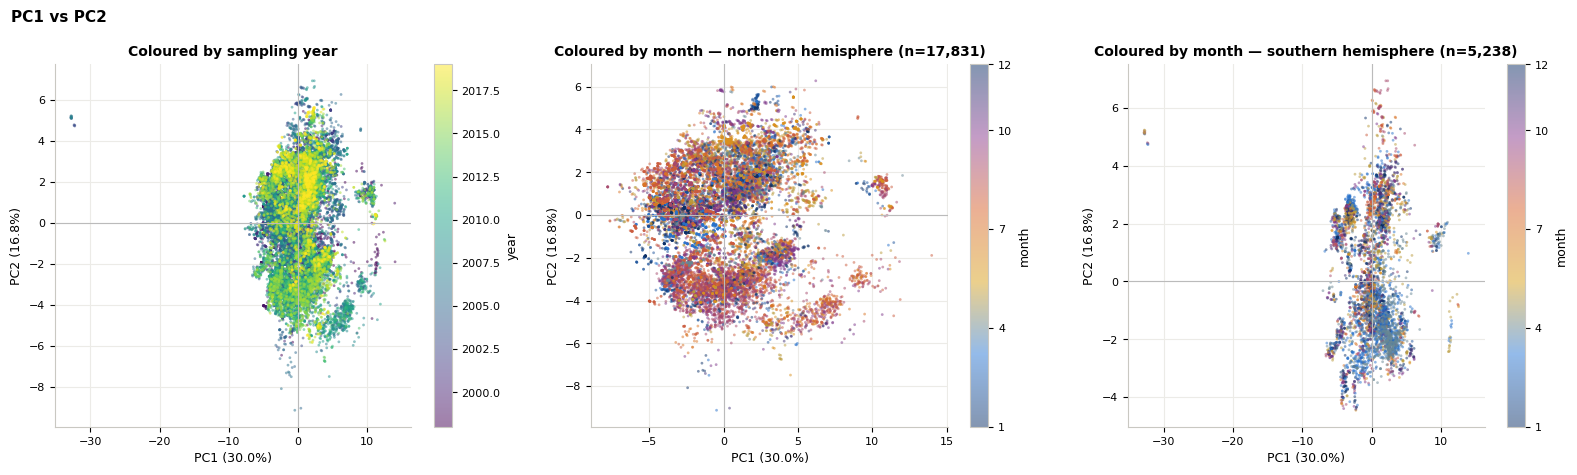

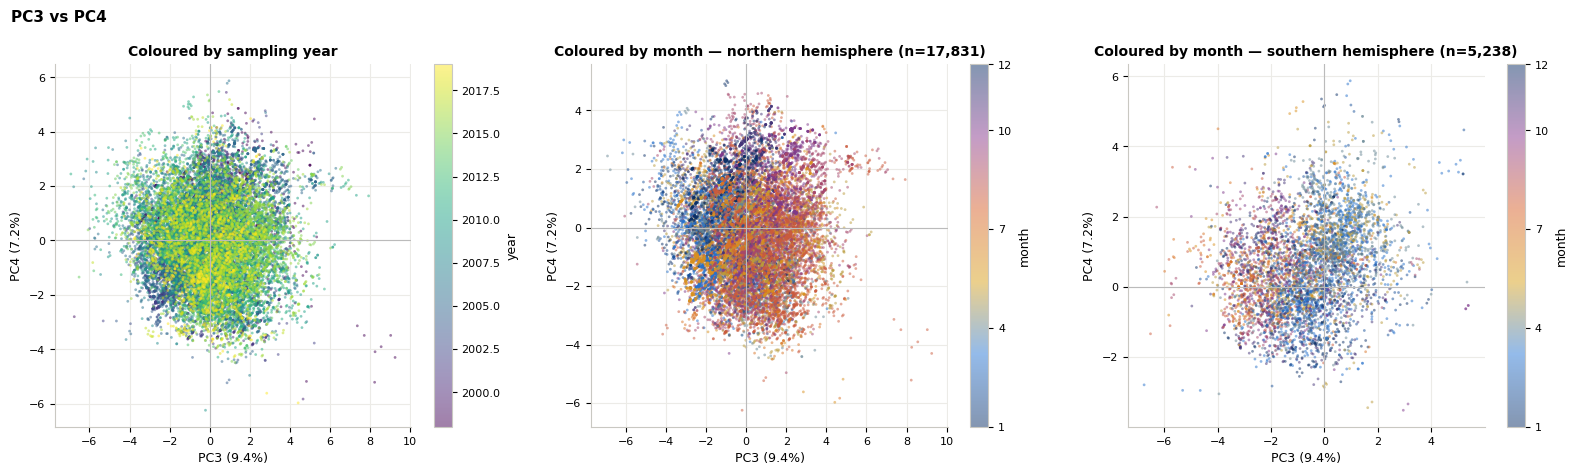

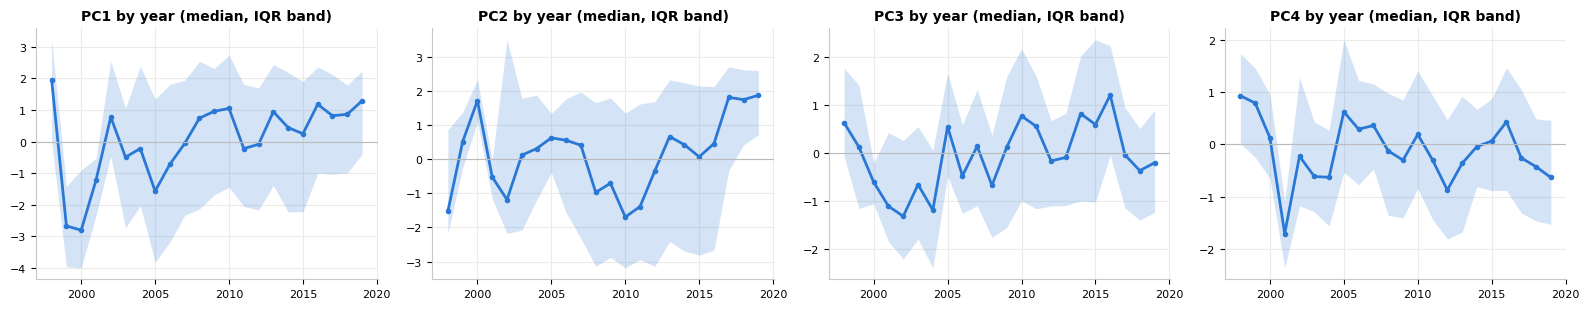

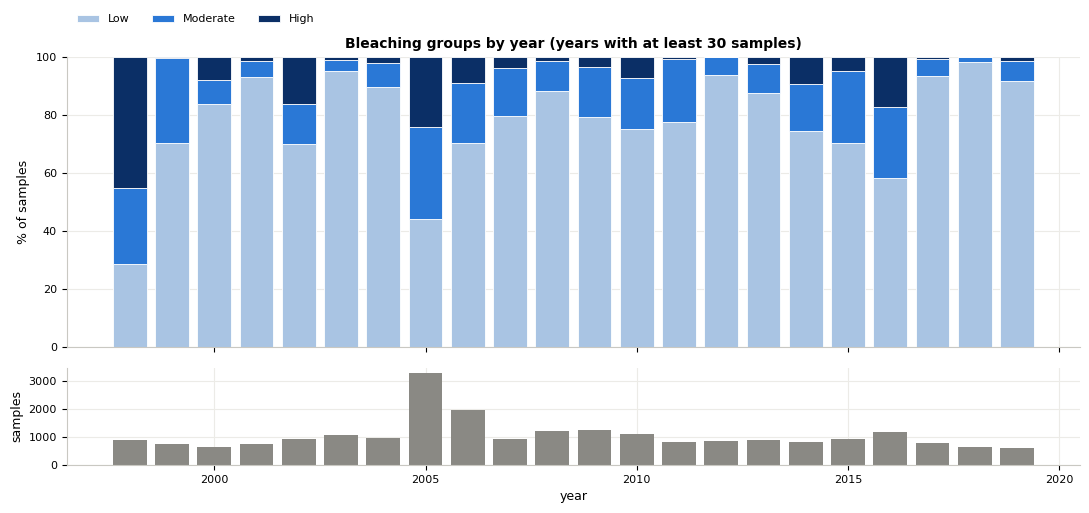

In [26]:
tables["time_associations"], tables["within_period_delta"] = temporal_associations(samples, scores.iloc[:, :SETTINGS["n_interpret"]], SETTINGS["periods"])
display(tables["time_associations"])
display(tables["within_period_delta"])
figures["time_pc1_pc2"] = plots.time_score_plot(samples, scores, result["variance"])
best_pair = sorted(group_table.cliffs_delta.abs().nlargest(2).index, key=lambda name: int(name[2:]))
figures["time_bleaching_components"] = plots.time_score_plot(samples, scores, result["variance"], *best_pair)
figures["annual_scores"], figures["annual_bleaching"] = plots.annual_patterns(samples, scores, SETTINGS["min_year_samples"])
for name in ["time_pc1_pc2", "time_bleaching_components", "annual_scores", "annual_bleaching"]:
    display(figures[name]); plt.close(figures[name])

## Step 15 · Findings and interpretation

The research question is whether PCA reveals major environmental patterns associated with bleaching severity. The principal result remains **partly**: the leading axes summarise environmental covariance, while smaller heat-stress axes show stronger bleaching associations. Country, ecoregion and source account for substantial score variation; consistent within-source contrasts support an association but do not establish causality. The variable-level tables address which original indicators distinguish High and Low, and the prediction diagnostic addresses the loss under compression.

The following numerical summary is generated from the current run. The retained prose describes the verified reference cohort; after changing data or settings, check all explanatory prose against the new tables before reporting. Pointwise cluster intervals, nominal legacy tests, and conditional CV answer different questions and are not interchangeable.

In [27]:
display(Markdown(results_markdown(samples, result, tables)))

The 23,069 events cover 1998–2019. 7 components retain 75.9% of environmental variance; PC1–PC2 retain 46.7%.

The strongest pooled High-versus-Low score differences are:

- **PC4**: Cliff's δ = +0.471, AUC = 0.736, weighted Cohen's d = +0.863; within-source combined δ = +0.349.

- **PC3**: Cliff's δ = +0.439, AUC = 0.720, weighted Cohen's d = +0.816; within-source combined δ = +0.279.


The retained components preserve 50.5% of the sample-level squared Mahalanobis separation between High and Low, relative to all 35 variables. This is a descriptive mean-separation ratio, not predictive accuracy or the fraction of all bleaching information.

Source-stratified and pooled estimates use different eligible populations and weights. Their difference cannot be interpreted as the causal fraction explained by survey source.


196 sites occur in both comparison groups. The original independent-site Welch p-values are retained as legacy results. The following site-cluster intervals provide pointwise uncertainty conditional on the fitted preprocessing/PCA, assuming sites are independent of one another.

- PC4: difference of site means +1.307, cluster 95% CI [+1.224, +1.393].

- PC3: difference of site means +1.387, cluster 95% CI [+1.297, +1.481].

### Practical implications and limits

Preserving the original recommendations, recent heat stress is a candidate focus for monitoring, while long-term geography alone is an incomplete guide. Keep original indicators alongside PCA summaries because compression discards some observed bleaching separation. Broaden High-bleaching observations outside the dominant survey source and examine results across regions and years.

Operational alert thresholds, causal protection benefits, and future predictive accuracy are **not established** by these retrospective associations. The exploratory grouped prediction check does not select or validate a monitoring threshold. Any operational rule needs separate external and temporal validation. Thermal families occupy 30 of the 35 inputs, and their prominence partly reflects feature representation. Source overlap, repeated sites, imputation, observation-method differences and unmeasured biological conditions remain limitations.

## Step 16 · Numerical preservation and organised export

Structural refactoring was checked against an executable reference of the original `coral_pca.ipynb` on the same input fingerprint. The table below compares eigenvalues, oriented loadings, effect sizes, multivariate distances and source-stratified contrasts. A changed input fingerprint is reported as incomparable rather than falsely passing an old reference.

Tables, figures, the sign-oriented fitted model, feature order, settings, software versions and fingerprints are exported together to `outputs/pca/`. The original sample-level and independent-site tests are retained as legacy outputs, alongside the corrected uncertainty and CV audits. No preprocessing file is overwritten.

In [28]:
tables["reference_validation"] = compare_reference(ROOT, result, tables)
display(tables["reference_validation"])
exports = export_analysis(ROOT, samples, result, tables, figures, SETTINGS, preprocessing_metadata)
display(exports)
print(f"Exported {len(tables)} analysis tables plus scores/interpretation, {len(figures)} figures and a reusable fitted model.")

,check,status,max_absolute_difference
0,Eigenvalues,pass,0
1,Oriented loadings,pass,0
2,Component Cliff delta,pass,0
3,Component Cohen d,pass,0
4,Hotelling squared distances,pass,0
5,Within-source PC3/PC4 delta,pass,0


,file
0,pca_explained_variance.csv
1,pca_loadings.csv
2,feature_contributions.csv
3,family_contributions.csv
4,pca_group_separation.csv
5,welch_tests_components.csv
6,welch_tests_variables.csv
7,hotelling_high_vs_low.csv
8,variable_high_vs_low.csv
9,variable_family_effects.csv


Exported 27 analysis tables plus scores/interpretation, 16 figures and a reusable fitted model.
